In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import torch
from torchao.quantization import quantize_, Int8WeightOnlyConfig
from diffusers import DiTPipeline
from copy import deepcopy
import torch.nn as nn 

model_id = "facebook/DiT-XL-2-256"
print("Loading baseline model components...")
pipe_fp = DiTPipeline.from_pretrained(model_id, torch_dtype = torch.float16).to("cuda")
pipe_quant = DiTPipeline.from_pretrained(model_id, torch_dtype = torch.float16).to("cuda")

quantize_(pipe_quant.transformer, Int8WeightOnlyConfig())

fp_outputs = {}
quant_outputs = {}

def get_activation_hook(name, storage_dict):
    def hook(model, input, output):
        if isinstance(output, tuple):
            storage_dict[name] = output[0].detach().cpu().float()
        else:
            storage_dict[name] = output.detach().cpu().float()
    return hook

print("Registering activation interceptor hooks...")
for name, module in pipe_fp.transformer.named_modules():
    if isinstance(module, nn.Linear) and ("block" in name):
        module.register_forward_hook(get_activation_hook(name, fp_outputs))

for name, module in pipe_quant.transformer.named_modules():
    if isinstance(module, nn.Linear) and ("block" in name):
        module.register_forward_hook(get_activation_hook(name, quant_outputs))

batch_size = 1
latent_channels = 4
spatial_size = 32

dummy_latents = torch.randn(batch_size, latent_channels, spatial_size, spatial_size, dtype = torch.float16, device = "cuda")
dummy_timestep = torch.tensor([50], dtype =torch.int32, device = "cuda")
dummy_class_labels = torch.tensor([1], dtype = torch.int32, device="cuda")

with torch.no_grad():
    pipe_fp.transformer(dummy_latents, timestep=dummy_timestep, class_labels=dummy_class_labels)
    pipe_quant.transformer(dummy_latents, timestep=dummy_timestep, class_labels=dummy_class_labels)

print("\n ---Layer-wise MSE evaluation results --- ")
layer_errors={}

for name in fp_outputs.keys():
    if name in quant_outputs:
        mse = torch.mean((fp_outputs[name] - quant_outputs[name])**2).item()
        layer_errors[name] = mse
        print(f"Layer: {name:<60} | MSE: {mse:.6f}")

worst_layers = sorted(layer_errors.items(), key=lambda x: x[1], reverse=True)[:10]
print("\nTop 5 Worst Degraded Layers (High Error Prone):")
for name, error in worst_layers:
    print(f"❌ {name:<60} | MSE: {error:.6f}")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Loading baseline model components...


model_index.json: 0.00B [00:00, ?B/s]

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/3 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/transformer: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/transformer.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
Expected types for id2label: (dict[int, str], <class 'NoneType'>), got typing.Dict[str, str].


Loading pipeline components...:   0%|          | 0/3 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/transformer: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/transformer.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
Expected types for id2label: (dict[int, str], <class 'NoneType'>), got typing.Dict[str, str].


Registering activation interceptor hooks...

 ---Layer-wise MSE evaluation results --- 
Layer: transformer_blocks.0.norm1.emb.timestep_embedder.linear_1    | MSE: 0.000008
Layer: transformer_blocks.0.norm1.emb.timestep_embedder.linear_2    | MSE: 0.000000
Layer: transformer_blocks.0.norm1.linear                            | MSE: 0.000003
Layer: transformer_blocks.0.attn1.to_q                              | MSE: 0.000051
Layer: transformer_blocks.0.attn1.to_k                              | MSE: 0.000080
Layer: transformer_blocks.0.attn1.to_v                              | MSE: 0.000142
Layer: transformer_blocks.0.attn1.to_out.0                          | MSE: 0.000388
Layer: transformer_blocks.0.ff.net.0.proj                           | MSE: 0.000109
Layer: transformer_blocks.0.ff.net.2                                | MSE: 0.000655
Layer: transformer_blocks.1.norm1.emb.timestep_embedder.linear_1    | MSE: 0.000008
Layer: transformer_blocks.1.norm1.emb.timestep_embedder.linear_2    | MS

In [2]:
import gc
[obj for obj in dir() if 'pipe' in obj.lower()]

['DiTPipeline', 'pipe_fp', 'pipe_quant']

Loading pipeline components...:   0%|          | 0/3 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/transformer: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/transformer.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--facebook--DiT-XL-2-256/snapshots/eab87f77abd5aef071a632f08807fbaab0b704d0/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
Expected types for id2label: (dict[int, str], <class 'NoneType'>), got typing.Dict[str, str].



Selective quantization summary:
  int4 layers : 152
  int8 layers : 54
  skipped     : 46

Generating images — fp16 baseline...


  0%|          | 0/50 [00:00<?, ?it/s]

Generating images — uniform int8...


  0%|          | 0/50 [00:00<?, ?it/s]

Generating images — MSE-selective...


/usr/local/lib/python3.12/dist-packages/diffusers/utils/pil_utils.py:41: RuntimeWarning: invalid value encountered in cast
  images = (images * 255).round().astype("uint8")


  0%|          | 0/50 [00:00<?, ?it/s]


Latency — fp16: 48.23s | int8 uniform: 53.25s | selective: 13.45s


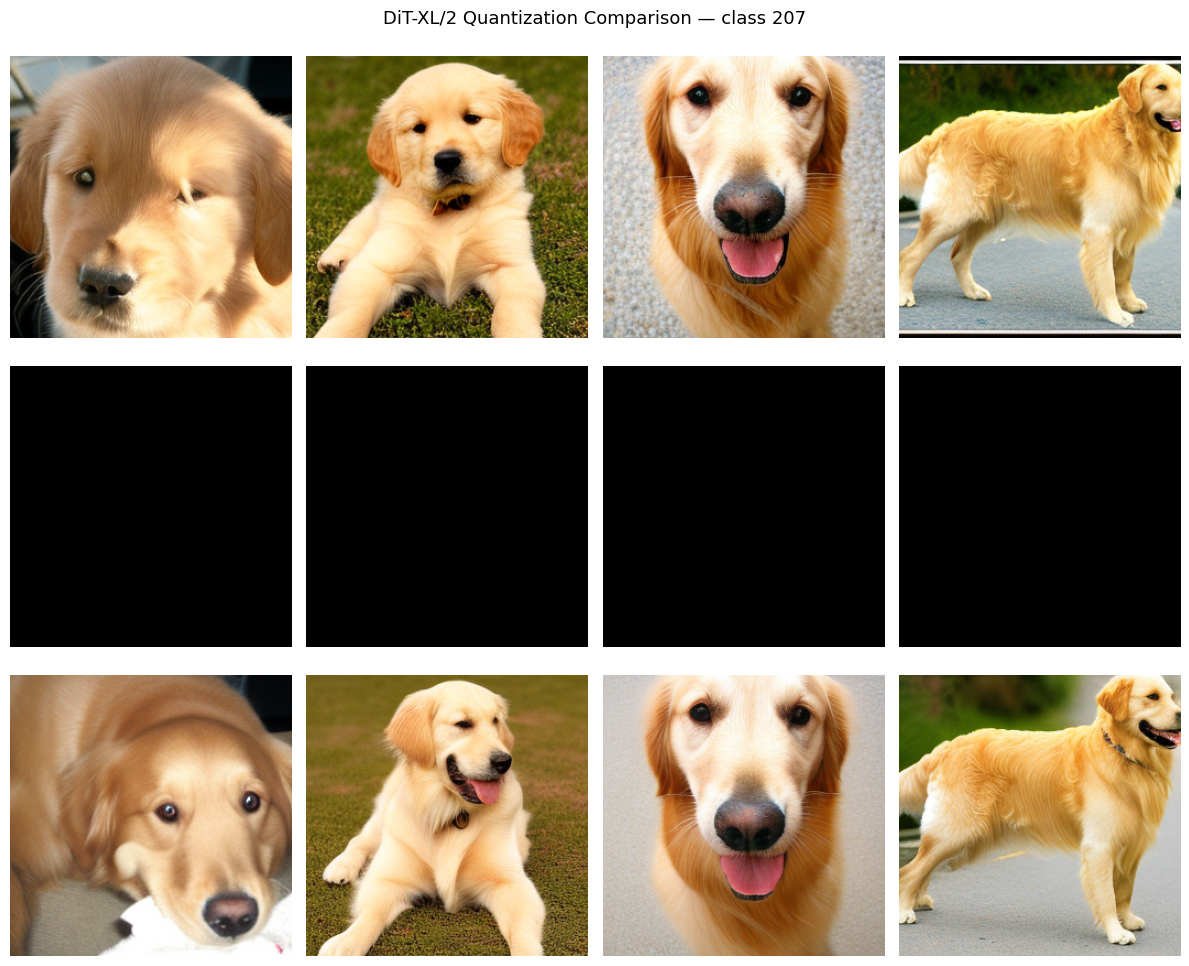

Saved → quantization_comparison.png


In [4]:
import time
import matplotlib.pyplot as plt
import numpy as np
from torchao.quantization import Int8DynamicActivationInt4WeightConfig, Int8WeightOnlyConfig
from torchao.quantization.granularity import PerGroup

def get_quant_config(mse):
    if mse < 0.001:
        return Int8DynamicActivationInt4WeightConfig()
    elif mse>0.01 : 
        return None
    else :
        return Int8WeightOnlyConfig()
    
# pipe_fp = deepcopy(base_pipe)
# pipe_quant = deepcopy(base_pipe)
quantize_(pipe_quant.transformer, Int8WeightOnlyConfig())

pipe_selective = DiTPipeline.from_pretrained(model_id, torch_dtype=torch.float16).to("cuda")

quantized_count = {"int4": 0, "int8": 0, "skipped": 0}

for name, module in pipe_selective.transformer.named_modules():
    if isinstance(module, nn.Linear) and ("block" in name):
        mse = layer_errors.get(name, float('inf'))
        config = get_quant_config(mse)
        if config is not None:
            try:
                quantize_(module, config)
                if mse < 0.001:
                    quantized_count["int4"] += 1
                else:
                    quantized_count["int8"] += 1
            except Exception as e:
                print(f"Failed to quantize {name}: {e}")
                quantized_count["skipped"] += 1
        else:
            quantized_count["skipped"] += 1

print(f"\nSelective quantization summary:")
print(f"  int4 layers : {quantized_count['int4']}")
print(f"  int8 layers : {quantized_count['int8']}")
print(f"  skipped     : {quantized_count['skipped']}")

CLASS_LABEL = 207  # golden retriever
NUM_IMAGES = 4
GENERATOR_SEED = 42

def generate_images(pipe, label, num_images, seed):
    generator = torch.Generator(device="cuda").manual_seed(seed)
    start = time.time()
    out = pipe(
        class_labels=[label] * num_images,
        generator=generator,
        num_inference_steps=50,
        output_type="pil"
    )
    elapsed = time.time() - start
    return out.images, elapsed

print("\nGenerating images — fp16 baseline...")
imgs_fp16, t_fp16 = generate_images(pipe_fp, CLASS_LABEL, NUM_IMAGES, GENERATOR_SEED)

print("Generating images — uniform int8...")
imgs_int8, t_int8 = generate_images(pipe_quant, CLASS_LABEL, NUM_IMAGES, GENERATOR_SEED)

print("Generating images — MSE-selective...")
imgs_selective, t_selective = generate_images(pipe_selective, CLASS_LABEL, NUM_IMAGES, GENERATOR_SEED)

print(f"\nLatency — fp16: {t_fp16:.2f}s | int8 uniform: {t_int8:.2f}s | selective: {t_selective:.2f}s")

# ── 4. Plot comparison ─────────────────────────────────────────────────────────

fig, axes = plt.subplots(3, NUM_IMAGES, figsize=(NUM_IMAGES * 3, 10))

labels = [
    f"FP16 baseline ({t_fp16:.1f}s)",
    f"Uniform INT8 ({t_int8:.1f}s)",
    f"MSE-Selective ({t_selective:.1f}s)",
]

for row, (imgs, label) in enumerate(zip([imgs_fp16, imgs_int8, imgs_selective], labels)):
    for col, img in enumerate(imgs):
        axes[row][col].imshow(img)
        axes[row][col].axis("off")
    axes[row][0].set_ylabel(label, fontsize=11, rotation=90, labelpad=10)

plt.suptitle(f"DiT-XL/2 Quantization Comparison — class {CLASS_LABEL}", fontsize=13)
plt.tight_layout()
plt.savefig("quantization_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → quantization_comparison.png")
